# Integração de Redes Neurais Artificiais à Engenharia
## Estudo de Caso: Predição de Propriedades Mecânicas em Impressão 3D

Este notebook demonstra o caminho desde a manipulação de dados brutos até a implementação de uma Rede Neural Artificial (RNA) para resolver problemas complexos de engenharia.

### Objetivo
Prever a **Resistência à Tração (Tension Strength)** de peças impressas em 3D com base nos parâmetros de configuração da impressora (input).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Configurações estéticas
sns.set(style="whitegrid")
%matplotlib inline

## 1. Manipulação e Limpeza de Dados

Na engenharia, os dados muitas vezes vêm de sensores ou logs experimentais. O primeiro passo é transformar esses dados em um formato que a RNA possa processar.

In [2]:
# Carregando o dataset
df = pd.read_csv('data.csv')

# Conversão de variáveis categóricas (Engenharia de Features)
# ABS = 0, PLA = 1
df['material'] = df['material'].map({'abs': 0, 'pla': 1})

# Grid = 0, Honeycomb = 1
df['infill_pattern'] = df['infill_pattern'].map({'grid': 0, 'honeycomb': 1})

print("Dimensões do dataset:", df.shape)
display(df.head())

Dimensões do dataset: (50, 12)


,layer_height,wall_thickness,infill_density,infill_pattern,nozzle_temperature,bed_temperature,print_speed,material,fan_speed,roughness,tension_strenght,elongation
0,0.02,8,90,0,220,60,40,0,0,25,18,1.2
1,0.02,7,90,1,225,65,40,0,25,32,16,1.4
2,0.02,1,80,0,230,70,40,0,50,40,8,0.8
3,0.02,4,70,1,240,75,40,0,75,68,10,0.5
4,0.02,6,90,0,250,80,40,0,100,92,5,0.7


## 2. Análise Exploratória (Foco em Engenharia)

Vamos observar como as variáveis se correlacionam com a resistência à tração.

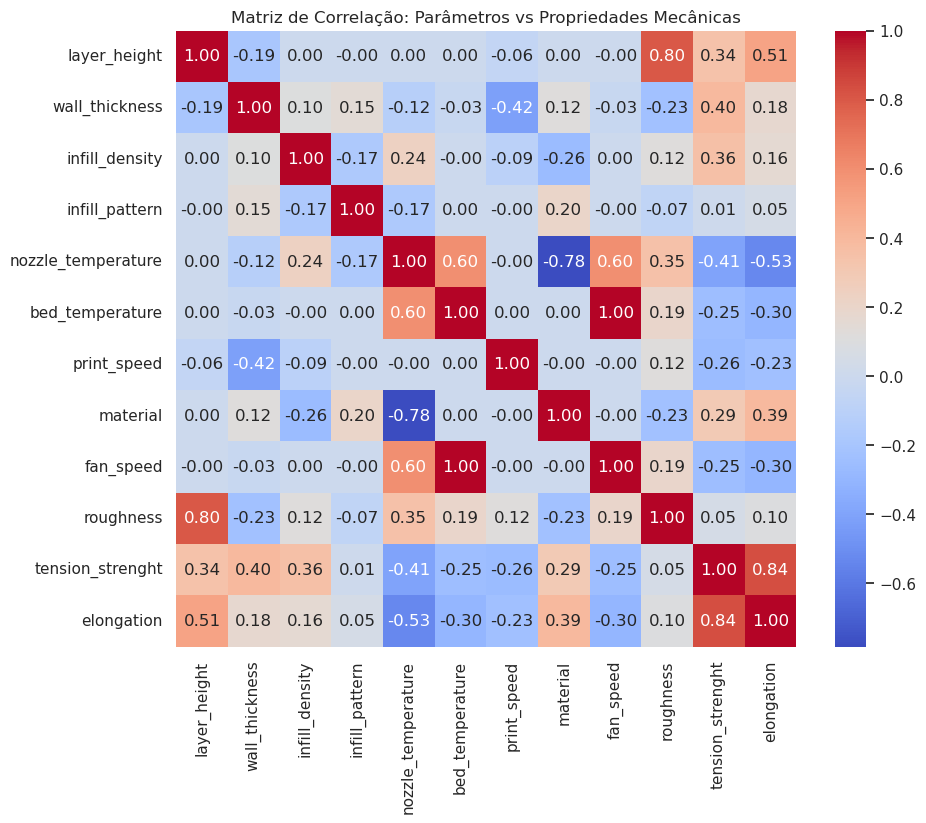

In [3]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação: Parâmetros vs Propriedades Mecânicas')
plt.show()

## 3. Preparação para a Rede Neural

Redes Neurais são sensíveis à escala dos dados. Valores como temperatura (250) e altura da camada (0.02) precisam ser normalizados.

In [4]:
# Definindo Inputs (X) e Target (y)
# Queremos prever tension_strenght com base nos parâmetros de impressão
X = df.drop(['tension_strenght', 'roughness', 'elongation'], axis=1)
y = df['tension_strenght']

# Divisão Treino/Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalonamento (Padronização Z-score)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Implementação da RNA (Multi-Layer Perceptron)

Utilizaremos o `MLPRegressor` do scikit-learn para criar uma rede com duas camadas ocultas.

In [5]:
# Definição da Arquitetura: 2 camadas ocultas com 16 e 8 neurônios
mlp = MLPRegressor(
    hidden_layer_sizes=(16, 8), 
    activation='relu', 
    solver='adam', 
    max_iter=3000, 
    random_state=42
)

# Treinamento
print("Treinando a Rede Neural...")
mlp.fit(X_train_scaled, y_train)
print("Treinamento concluído.")

Treinando a Rede Neural...
Treinamento concluído.


/home/enzosarmento/anaconda3/envs/Titanic/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Validação e Resultados para o Relatório

Como o modelo se comporta com dados que ele nunca viu?

Erro Médio Absoluto: 6.60 MPa
Coeficiente de Determinação (R²): 0.1110


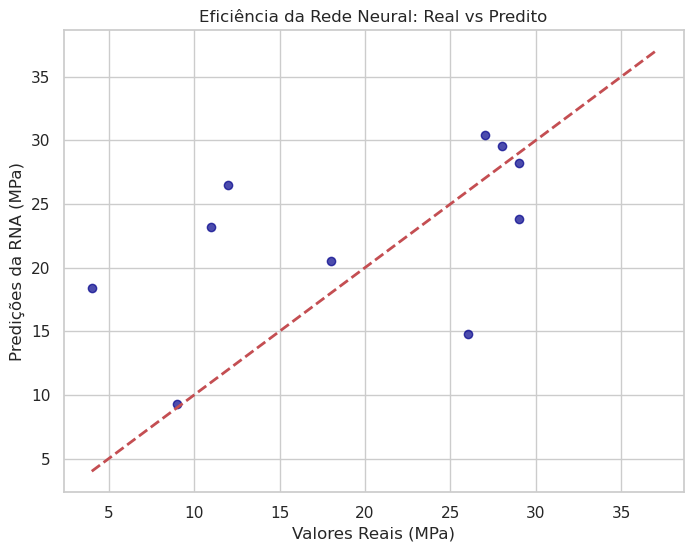

In [6]:
y_pred = mlp.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Erro Médio Absoluto: {mae:.2f} MPa")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")

# Visualização Real vs Predito
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='darkblue', alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Valores Reais (MPa)')
plt.ylabel('Predições da RNA (MPa)')
plt.title('Eficiência da Rede Neural: Real vs Predito')
plt.show()

## Conclusão para Integração na Engenharia

A aplicação de Redes Neurais neste cenário permite:
1. **Redução de Custos:** Menos necessidade de ensaios destrutivos físicos.
2. **Otimização de Processos:** Identificar quais parâmetros (como `wall_thickness` ou `infill_density`) têm maior impacto na integridade estrutural.
3. **Gêmeos Digitais:** Criar um modelo virtual que simula o comportamento da impressora antes mesmo da fabricação começar.